In [131]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats 
import missingno as msno
from sklearn.impute import KNNImputer

Se carga el data set completo

In [132]:
FILENAME = "dataset_consolidado_complete.csv"
datapath_completo = os.path.join("..","..","data","clean",FILENAME)
df_completo = pd.read_csv(datapath_completo)


C:\Users\ireni\AppData\Local\Temp\ipykernel_21712\1541478545.py:3: DtypeWarning: Columns (154: Nivel Silo Bagazo Norte (1), 178: KW Trafo 8, 336: Totalizador Bba P1, 337: Totalizador Bba P2, 338: Totalizador Bba P4, 339: Totalizador Bba Envasado, 340: Totalizador Bba P51) have mixed types. Specify dtype option on import or set low_memory=False.
  df_completo = pd.read_csv(datapath_completo)


In [133]:
df_completo = df_completo.replace(' ', np.nan)
columnas_numericas = ~df_completo.columns.isin(["DIA", "HORA"])
df_completo.loc[:, columnas_numericas] = (
    df_completo.loc[:, columnas_numericas]
    .apply(pd.to_numeric, errors="coerce")
)

Creacion del dataframe diario

In [134]:
df_temp = df_completo.groupby('DIA').last().reset_index()
hora_cierre = '23:59:00'
df_diario = df_temp[df_temp['HORA'] == hora_cierre].copy()


dias_eliminados = len(df_temp) - len(df_diario)
print(f"Se eliminaron {dias_eliminados} días incompletos que no llegaron a las 23:59.")

fecha_siguiente = pd.to_datetime(df_diario["DIA"].shift(-1))
fecha_actual = pd.to_datetime(df_diario["DIA"])
diferencia_dia_siguiente = fecha_siguiente - fecha_actual
indices_a_borrar = df_diario.index[diferencia_dia_siguiente > pd.Timedelta(days=1)]
df_diario = df_diario.drop(index=indices_a_borrar)
df_diario['target_Frio_kW_next'] = df_diario['Frio (Kw)'].shift(-1)

df_diario = df_diario.dropna(subset=['target_Frio_kW_next']).copy()

#Features a utilizar (conocimiento del dominio)

features_a_utilizar = [
    "DIA",
    "KW Mycom 1",
    "KW Mycom 2",
    "KW Mycom 3",
    "KW Mycom 4",
    "KW Mycom 5",
    "KW Mycom 6",
    "KW Mycom 7",
    "EE Frio / Hl",
    "KW Bba Glicol Sala MAq",
    "KW Bba Glicol Bod",
    "KW Enfr Agua Cocina",
    "Hl de Mosto",
    "Hl Producido Bodega",
    "Hl Cerveza Filtrada",
    "Hl Cerveza Envasada",
    "Hl Cerveza Cocina",
    "Elaboracion (Kw)",
    "Bodega (Kw)",
    "Envasado (Kw)",
    "Servicios (Kw)",
    "Frio (Kw)",
    "Agua Planta (Hl)",
    "Agua Helada Cocina",
    "Glicol Paste L3",
    "Temp Tq Intermedio",
    "Gas Planta (Mj)",
    "Vapor Elaboracion (Kg)",
    "Totalizador_Bodega",
    "Totalizador_Tq_Pulmon",
    "Tot Fermantacion_Cocina",
    "Tot Reposo Inferior",
    "Tot  Reposo Superior",
    "Tot  Trasiego",
    "Tot A10/20",
    "Tot A40/240/50/60/Centec/Filtro",
    "Tot  A130/330/430",
    "Tot L3, L4 y Planta de CO2",
    # Variables agregadas tras realizar EDA
    "Agua Cond REC",
    "KW Gral Planta",
    "Planta (Kw)",
    "Sala Maq (Kw)",
    "KW Trafo 4",
    "KW Trafo 5", 
    'KW Trafo 8', 
    'KW Trafo 11', 
    'KW Trafo 12',
    'KW Trafo 9', 
    'KW Trafo 10',
    "KW Cond 5. 6 y 9",
    "Produccion (Hl)",
    "Aire Producido (M3)",
    "Totalizador Sistema Kaeser"
]

df_completo["HORA"] = df_completo["HORA"].astype(str)

#días donde el target no se reinicio a las 00:00 (Se obtuvieron del eda)
dias_sin_reinicio = df_completo[(df_completo["HORA"] == "00:00:00") & (df_completo["Frio (Kw)"] != 0)]["DIA"]
df_diario = df_diario.drop(index= df_diario[df_diario["DIA"].isin(dias_sin_reinicio)].index)


target = ["target_Frio_kW_next"]
df_diario = df_diario[features_a_utilizar + target].copy()


Se eliminaron 5 días incompletos que no llegaron a las 23:59.


C:\Users\ireni\AppData\Local\Temp\ipykernel_21712\3907674206.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp = df_completo.groupby('DIA').last().reset_index()


## Análisis patron de valores faltantes

In [135]:
tabla_nulos = pd.DataFrame(
    {"Valores Nulos": df_diario.isna().sum(),
     "Porcentaje (%)": df_diario.isna().mean() * 100,
    })

tabla_nulos = (
    tabla_nulos.style.set_caption("Resumen de Valores Nulos por Columna")
    .format({"Porcentaje (%)": "{:.2f}%"})
)

display(tabla_nulos)

,Valores Nulos,Porcentaje (%)
DIA,0,0.00%
KW Mycom 1,0,0.00%
KW Mycom 2,0,0.00%
KW Mycom 3,0,0.00%
KW Mycom 4,0,0.00%
KW Mycom 5,0,0.00%
KW Mycom 6,0,0.00%
KW Mycom 7,0,0.00%
EE Frio / Hl,21,1.81%
KW Bba Glicol Sala MAq,0,0.00%


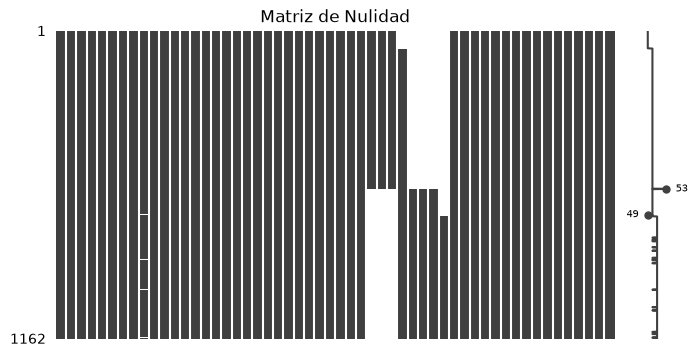

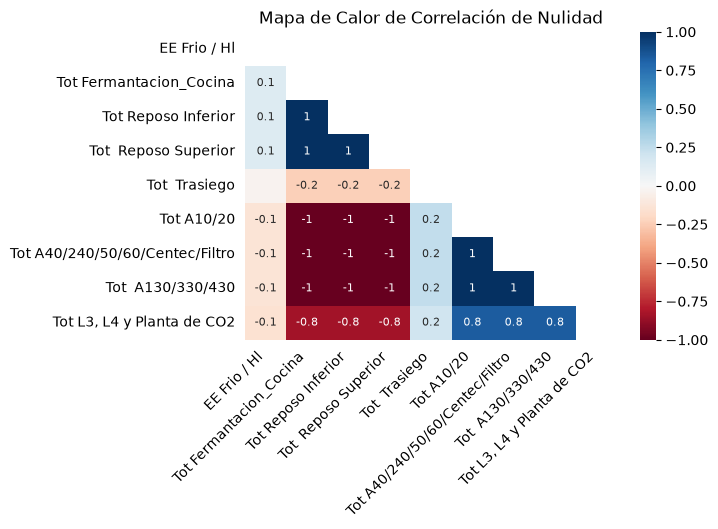

In [136]:
msno.matrix(df_diario, figsize=(8,4), fontsize=8)
plt.title("Matriz de Nulidad")
plt.show()

msno.heatmap(df_diario, figsize=(6,4), fontsize=10)
plt.title("Mapa de Calor de Correlación de Nulidad")
plt.show()

La variables con alto porcentajes de valores nulos además presentan una gran correlación de nulidad entre ellas. Se decidió eliminarlas por problematicas.

In [137]:
pd.set_option("display.max_columns", None)
display(df_diario)

,DIA,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,EE Frio / Hl,KW Bba Glicol Sala MAq,KW Bba Glicol Bod,KW Enfr Agua Cocina,Hl de Mosto,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza Cocina,Elaboracion (Kw),Bodega (Kw),Envasado (Kw),Servicios (Kw),Frio (Kw),Agua Planta (Hl),Agua Helada Cocina,Glicol Paste L3,Temp Tq Intermedio,Gas Planta (Mj),Vapor Elaboracion (Kg),Totalizador_Bodega,Totalizador_Tq_Pulmon,Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,Tot Trasiego,Tot A10/20,Tot A40/240/50/60/Centec/Filtro,Tot A130/330/430,"Tot L3, L4 y Planta de CO2",Agua Cond REC,KW Gral Planta,Planta (Kw),Sala Maq (Kw),KW Trafo 4,KW Trafo 5,KW Trafo 8,KW Trafo 11,KW Trafo 12,KW Trafo 9,KW Trafo 10,KW Cond 5. 6 y 9,Produccion (Hl),Aire Producido (M3),Totalizador Sistema Kaeser,target_Frio_kW_next
0,2020-07-01,0,3600.0,0.0,0,0.0,1013.0,4342.0,333.139535,467.0,1990.0,0.0,0.0,43.000,0.0,86.0,0.00,2027.25,2968.00,594.0,23848.0,14325.0,10280.000000,0.0,0.0,-3.0,150775.730528,6779.44000,733.3100,1775.0,570.17,6323.06,0.1,NaN,NaN,NaN,NaN,NaN,231.210000,29529.0,27637.270000,17080.0,2636.0,1124.0,1186.56,11920.0,3639.0,1637.75,6046.25,614.0,2398.000000,31871.0,31871.0,23954.0
1,2020-07-02,701,5848.0,1362.0,2238,0.0,1062.0,5641.0,3.419545,777.0,2359.0,5.0,2907.0,7005.025,13361.0,10667.0,3343.05,5391.13,5595.88,16522.0,38033.0,23954.0,13970.000000,3452.0,0.0,1.0,469499.449248,45103.22000,5484.0600,14295.0,694.08,5349.47,0.8,NaN,NaN,NaN,NaN,NaN,284.210000,65592.0,54409.810000,27216.0,5792.0,1654.0,3095.53,18592.0,7248.0,17288.75,10108.13,1073.0,25148.500000,51079.0,51079.0,28268.0
2,2020-07-03,328,5980.0,5356.0,3321,0.0,1043.0,4792.0,3.787626,824.0,2615.0,13.0,4829.0,7463.250,9493.0,10024.0,4902.50,6437.75,6237.50,14818.0,42565.5,28268.0,36300.000000,5495.0,0.0,-1.0,548270.265952,61087.32000,5146.2300,8366.0,400.66,4965.47,0.5,NaN,NaN,NaN,NaN,NaN,297.530000,68039.0,65685.590000,31386.0,6863.0,1665.5,1404.94,18486.0,11349.0,17260.75,9177.75,1083.0,29365.000000,62958.0,62958.0,24246.0
3,2020-07-04,0,6040.0,1407.0,5029,0.0,325.0,4901.0,1.870213,765.0,1891.0,28.0,7828.0,12964.300,8450.0,12223.0,13705.60,5694.25,4810.75,18696.0,39650.0,24246.0,40120.000000,8376.0,0.0,2.0,635538.945472,80588.95000,3575.0800,5081.0,447.89,5040.93,1.0,NaN,NaN,NaN,NaN,NaN,279.630000,69857.0,67098.540000,28070.0,7489.0,1648.0,6043.81,20510.0,7586.0,18709.50,6717.25,1031.0,32150.800000,69435.0,69435.0,29885.0
4,2020-07-05,0,6381.0,2043.0,5501,0.0,2568.0,6222.0,3.354482,786.0,2406.0,21.0,6406.0,8908.975,12894.0,8358.0,9459.95,7148.25,6394.75,14831.0,45385.0,29885.0,38940.000000,7971.0,0.0,-2.0,553697.930928,78034.90000,4823.7500,12559.0,400.06,5690.25,0.2,NaN,NaN,NaN,NaN,NaN,282.030000,73431.0,70600.640000,33463.0,7249.0,1645.0,5820.25,22212.0,8410.0,15220.50,9527.25,1077.0,30793.900000,66431.0,66431.0,24449.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1183,2023-10-20,3549,0.0,0.0,576,1279.0,0.0,960.0,NaN,1198.0,2985.0,0.0,0.0,0.000,1541.0,0.0,0.00,3976.00,4619.00,515.0,20273.0,11931.0,12257.954102,0.0,0.0,0.0,167237.171455,9852.87500,858.6250,2369.0,NaN,NaN,NaN,1458.1875,330.125,1636.750,6879.625,76.40625,85.300781,28064.0,26515.660000,14490.0,2162.0,4143.0,492.0,10640.0,60.0,1900.00,7582.00,323.0,5435.917969,19749.0,19749.0,9481.0
1184,2023-10-21,129,0.0,1736.0,0,1954.0,0.0,196.0,NaN,1041.0,2996.0,0.0,0.0,0.000,0.0,0.0,0.00,2383.00,3119.00,452.0,16977.0,9481.0,7468.889160,0.0,0.0,0.0,131153.378545,6476.84375,0.0000,1649.0,NaN,NaN,NaN,0.0000,232.375,2194.000,6922.250,40.12500,68.298828,22953.0,21627.800000,9793.0,3979.0,4788.0,492.5,3216.0,1754.0,1778.00,5818.00,330.0,2979.067383,15961.0,15961.0,11587.0
1185,2023-10-22,0,0.0,0.0,0,4094.0,0.0,1814.0,2.782861,1344.0,2920.0,0.0,3978.0,4163.700,0.0,1167.0,7160.40,3200.00,2788.00,2758.0,208

In [138]:
df_con_nulos =  df_diario.isna().mean() * 100 
columnas_con_nulos = df_con_nulos[df_con_nulos > 40].index

df_diario = df_diario.drop(columns=columnas_con_nulos)



In [139]:
mycoms = df_diario.columns[df_diario.columns.str.contains("Mycom")]
df_diario["Kw Mycom Mean"] = df_diario.loc[:, mycoms].mean(axis=1, skipna=True)
df_diario = df_diario.drop(columns=mycoms, errors= "ignore")
df_diario.columns

Index(['DIA', 'EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'KW Enfr Agua Cocina', 'Hl de Mosto', 'Hl Producido Bodega',
       'Hl Cerveza Filtrada', 'Hl Cerveza Envasada', 'Hl Cerveza Cocina',
       'Elaboracion (Kw)', 'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)',
       'Frio (Kw)', 'Agua Planta (Hl)', 'Agua Helada Cocina',
       'Glicol Paste L3', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Trafo 4', 'KW Trafo 5', 'KW Trafo 8',
       'KW Trafo 11', 'KW Trafo 12', 'KW Trafo 9', 'KW Trafo 10',
       'KW Cond 5. 6 y 9', 'Produccion (Hl)', 'Aire Producido (M3)',
       'Totalizador Sistema Kaeser', 'target_Frio_kW_next', 'Kw Mycom Mean'],
      dtype='str')

In [140]:
trafos = df_diario.columns[df_diario.columns.str.contains("Trafo")]
df_diario["Kw Trafo Mean"] = df_diario.loc[:, trafos].mean(axis=1, skipna=True) 
df_diario = df_diario.drop(columns=trafos, errors= "ignore")

In [141]:
df_diario.columns

Index(['DIA', 'EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'KW Enfr Agua Cocina', 'Hl de Mosto', 'Hl Producido Bodega',
       'Hl Cerveza Filtrada', 'Hl Cerveza Envasada', 'Hl Cerveza Cocina',
       'Elaboracion (Kw)', 'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)',
       'Frio (Kw)', 'Agua Planta (Hl)', 'Agua Helada Cocina',
       'Glicol Paste L3', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Aire Producido (M3)', 'Totalizador Sistema Kaeser',
       'target_Frio_kW_next', 'Kw Mycom Mean', 'Kw Trafo Mean'],
      dtype='str')

In [142]:
ceros = (df_diario==0).sum().sort_values(ascending=False)/df_diario.shape[0]*100
df_diario = df_diario.drop(columns=ceros[ceros>50].index)

In [143]:
numericas = df_diario.columns[~df_diario.columns.isin(["DIA", "HORA"])]

In [144]:
numericas

Index(['EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'Hl de Mosto', 'Hl Producido Bodega', 'Hl Cerveza Filtrada',
       'Hl Cerveza Envasada', 'Hl Cerveza Cocina', 'Elaboracion (Kw)',
       'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)', 'Frio (Kw)',
       'Agua Planta (Hl)', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Aire Producido (M3)', 'Totalizador Sistema Kaeser',
       'target_Frio_kW_next', 'Kw Mycom Mean', 'Kw Trafo Mean'],
      dtype='str')

## Tratamiento de nulos


In [145]:
df_numericas = df_diario[numericas].copy()
knn_imputer = KNNImputer(n_neighbors =5)
df_knn_imputed = pd.DataFrame(knn_imputer.fit_transform(df_numericas), columns=df_numericas.columns)


In [146]:
df_knn_imputed["DIA"] = df_diario["DIA"].copy()


In [147]:
df_knn_imputed

,EE Frio / Hl,KW Bba Glicol Sala MAq,KW Bba Glicol Bod,Hl de Mosto,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza Cocina,Elaboracion (Kw),Bodega (Kw),Envasado (Kw),Servicios (Kw),Frio (Kw),Agua Planta (Hl),Temp Tq Intermedio,Gas Planta (Mj),Vapor Elaboracion (Kg),Totalizador_Bodega,Totalizador_Tq_Pulmon,Tot Trasiego,Agua Cond REC,KW Gral Planta,Planta (Kw),Sala Maq (Kw),KW Cond 5. 6 y 9,Produccion (Hl),Aire Producido (M3),Totalizador Sistema Kaeser,target_Frio_kW_next,Kw Mycom Mean,Kw Trafo Mean,DIA
0,333.139535,467.0,1990.0,0.0,43.000,0.0,86.0,0.00,2027.25,2968.00,594.0,23848.0,14325.0,10280.000000,-3.0,150775.730528,6779.44000,733.3100,1775.0,98.33575,231.210000,29529.0,27637.270000,17080.0,614.0,2398.000000,31871.0,31871.0,23954.0,1279.285714,4027.080000,2020-07-01
1,3.419545,777.0,2359.0,2907.0,7005.025,13361.0,10667.0,3343.05,5391.13,5595.88,16522.0,38033.0,23954.0,13970.000000,1.0,469499.449248,45103.22000,5484.0600,14295.0,2092.11000,284.210000,65592.0,54409.810000,27216.0,1073.0,25148.500000,51079.0,51079.0,28268.0,2407.428571,9111.201429,2020-07-02
2,3.787626,824.0,2615.0,4829.0,7463.250,9493.0,10024.0,4902.50,6437.75,6237.50,14818.0,42565.5,28268.0,36300.000000,-1.0,548270.265952,61087.32000,5146.2300,8366.0,1119.12200,297.530000,68039.0,65685.590000,31386.0,1083.0,29365.000000,62958.0,62958.0,24246.0,2974.285714,9458.134286,2020-07-03
3,1.870213,765.0,1891.0,7828.0,12964.300,8450.0,12223.0,13705.60,5694.25,4810.75,18696.0,39650.0,24246.0,40120.000000,2.0,635538.945472,80588.95000,3575.0800,5081.0,1551.25800,279.630000,69857.0,67098.540000,28070.0,1031.0,32150.800000,69435.0,69435.0,29885.0,2528.857143,9814.794286,2020-07-04
4,3.354482,786.0,2406.0,6406.0,8908.975,12894.0,8358.0,9459.95,7148.25,6394.75,14831.0,45385.0,29885.0,38940.000000,-2.0,553697.930928,78034.90000,4823.7500,12559.0,1769.86200,282.030000,73431.0,70600.640000,33463.0,1077.0,30793.900000,66431.0,66431.0,24449.0,3245.000000,10012.000000,2020-07-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1157,79.315336,1198.0,2985.0,0.0,0.000,1541.0,0.0,0.00,3976.00,4619.00,515.0,20273.0,11931.0,12257.954102,0.0,167237.171455,9852.87500,858.6250,2369.0,1458.18750,85.300781,28064.0,26515.660000,14490.0,323.0,5435.917969,19749.0,19749.0,9481.0,909.142857,3854.142857,2023-09-24
1158,76.974643,1041.0,2996.0,0.0,0.000,0.0,0.0,0.00,2383.00,3119.00,452.0,16977.0,9481.0,7468.889160,0.0,131153.378545,6476.84375,0.0000,1649.0,0.00000,68.298828,22953.0,21627.800000,9793.0,330.0,2979.067383,15961.0,15961.0,11587.0,573.571429,3117.928571,2023-09-25
1159,2.782861,1344.0,2920.0,3978.0,4163.700,0.0,1167.0,7160.40,3200.00,2788.00,2758.0,20821.0,11587.0,17313.110352,0.0,295228.456226,35214.46875,7.9375,2863.0,0.00000,67.599609,31956.0,30287.570000,11873.0,328.0,11381.960449,26134.0,26134.0,10123.0,844.000000,4391.071429,2023-09-26
1160,20.765128,1093.0,2983.0,0.0,487.500,0.0,975.0,0.00,2329.00,2882.00,3339.0,18771.0,10123.0,12697.983398,0.0,217570.326705,6922.65625,0.0000,3244.0,0.00000,58.400391,30480.0,28667.480000,10395.0,334.0,5431.079102,22882.0,22882.0,10360.0,657.857143,4142.285714,2023-09-27


## Tratamiento de valores extremos


In [148]:
df_diario_sin_outliers = df_knn_imputed.copy()

for f in numericas: 
    Q1 = df_diario_sin_outliers[f].quantile(0.25)
    Q3 = df_diario_sin_outliers[f].quantile(0.75)
    P99 = df_diario_sin_outliers[f].quantile(0.99)
    IQR = Q3 - Q1

    #no pusimos 1.5 ya que nos parece muy estricto
    outliers = df_diario_sin_outliers[(df_diario_sin_outliers[f] < - 3 * IQR + Q1 ) | (df_diario_sin_outliers[f] >  3 * IQR + Q3 )].index
    
    if f == 'target_Frio_kW_next':
        df_diario_sin_outliers = df_diario_sin_outliers.drop(index=outliers)
    else:
        #df_diario_sin_outliers[f] = df_diario_sin_outliers[f].astype("float64")
        df_diario_sin_outliers.loc[outliers, f] = P99
